# Lens 1 — Notebook 02: Revenue Data Preparation & Feature Engineering
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102664`  
**Lens:** 1 — Revenue Forecasting  
**Role:** Revenue Data Preparation & Feature Engineering

---

## Notebook Purpose
This notebook transforms the cleaned daily revenue series (produced in NB01) into a **machine-learning-ready feature matrix** that is completely free of temporal leakage.

### Key Principles Applied:
1. **Zero target leakage** — every feature uses only information available *before* the prediction day
2. **Continuous calendar** — missing trading days imputed as 0 to preserve time-series ordering
3. **Interpretable features** — each feature group has a clear business meaning
4. **Defensible decisions** — every engineering choice is documented with its justification

### Rubric Alignment:
| Criterion | Coverage |
|---|---|
| Preprocessing & feature-engineering decisions | Justified missing-value handling, outlier treatment, leakage prevention |
| Data understanding | Rolling stats reveal additional temporal structure |
| Reproducibility | Fixed seeds; deterministic pipeline; outputs saved to CSV |

---

## Section Overview
1. Environment Setup
2. Load & Validate Revenue Series
3. Continuous Calendar Reindexing & Missing Day Imputation
4. Calendar / Cyclical Feature Engineering
5. Autoregressive Lag Features
6. Rolling Window Statistics (Leakage-Free)
7. Feature Matrix Assembly & Validation
8. Leakage Verification Test
9. Save Feature Matrices
10. Feature Engineering Decision Log

---
## 1. Environment Setup

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Environment initialised.")

Environment initialised.


---
## 2. Load & Validate Revenue Series

In [2]:
REV_PATH = '../data/processed/daily_revenue.csv'

rev_df = pd.read_csv(REV_PATH, parse_dates=['Date'])
rev_df = rev_df.sort_values('Date').reset_index(drop=True)

print(f"Loaded: {len(rev_df):,} rows")
print(f"Date range: {rev_df['Date'].min().date()} → {rev_df['Date'].max().date()}")
print(f"Columns: {list(rev_df.columns)}")
print()
print(rev_df.head(10))

Loaded: 895 rows
Date range: 2024-03-27 → 2026-09-07
Columns: ['Date', 'Revenue']

        Date  Revenue
0 2024-03-27   2050.0
1 2024-03-28  40540.0
2 2024-03-29  12870.0
3 2024-03-30  45474.0
4 2024-03-31  17210.0
5 2024-04-01  34910.0
6 2024-04-02  38060.0
7 2024-04-03      0.0
8 2024-04-04  23430.0
9 2024-04-05  33210.0


In [3]:
# Validation checks
assert rev_df['Date'].duplicated().sum() == 0, "Duplicate dates detected!"
assert rev_df['Revenue'].isna().sum() == 0, "NaN values in Revenue!"
assert (rev_df['Revenue'] < 0).sum() == 0, "Negative revenue values!"

n_days = (rev_df['Date'].max() - rev_df['Date'].min()).days + 1
n_gaps = n_days - len(rev_df)
print(f"Calendar days in span: {n_days}")
print(f"Rows in dataframe    : {len(rev_df)}")
print(f"Missing calendar days: {n_gaps}")
print(f"Zero-revenue days    : {(rev_df['Revenue'] == 0).sum()}")

Calendar days in span: 895
Rows in dataframe    : 895
Missing calendar days: 0
Zero-revenue days    : 33


---
## 3. Continuous Calendar Reindexing & Missing Day Imputation

**Why this matters:** Time-series lag features require a *contiguous* date index. If days are skipped, `df.shift(1)` would align the wrong past observation to each prediction point, introducing systematic errors.

**Imputation decision:** Restaurant closure days (no transactions) → Revenue = 0.0  
**Rationale:** Zero revenue is the factually correct value for days the restaurant did not trade. Imputing the mean or median would create false signal.

In [4]:
full_idx = pd.date_range(rev_df['Date'].min(), rev_df['Date'].max(), freq='D')
rev_cont = rev_df.set_index('Date').reindex(full_idx, fill_value=0.0).reset_index()
rev_cont.columns = ['Date', 'Revenue']

print(f"Rows after reindex: {len(rev_cont):,}")
print(f"Added (closure) days: {len(rev_cont) - len(rev_df)}")

# Flag closure days
rev_cont['is_closed'] = (rev_cont['Revenue'] == 0).astype(int)
print(f"is_closed=1 days: {rev_cont['is_closed'].sum()}")

Rows after reindex: 895
Added (closure) days: 0
is_closed=1 days: 33


---
## 4. Calendar / Cyclical Feature Engineering

Calendar features encode the *structural* position of each day in time.  
**Critical design choice — cyclical encoding:**  
Day-of-week (0=Mon, 6=Sun) encoded as an integer would imply Mon and Sun are far apart, but *cyclically* they are adjacent. We use sin/cos transforms to preserve this cyclical structure:

$$\text{dow\_sin} = \sin\left(\frac{2\pi \cdot \text{DOW}}{7}\right), \quad \text{dow\_cos} = \cos\left(\frac{2\pi \cdot \text{DOW}}{7}\right)$$

The same approach is applied to month-of-year.

In [5]:
df_feat = rev_cont.copy()

# --- Raw calendar primitives ---
df_feat['day_of_week']    = df_feat['Date'].dt.dayofweek          # 0=Mon, 6=Sun
df_feat['day_of_month']   = df_feat['Date'].dt.day
df_feat['month']          = df_feat['Date'].dt.month
df_feat['quarter']        = df_feat['Date'].dt.quarter
df_feat['week_of_year']   = df_feat['Date'].dt.isocalendar().week.astype(int)
df_feat['year']           = df_feat['Date'].dt.year

# --- Cyclical sin/cos encodings ---
df_feat['dow_sin']        = np.sin(2 * np.pi * df_feat['day_of_week'] / 7)
df_feat['dow_cos']        = np.cos(2 * np.pi * df_feat['day_of_week'] / 7)
df_feat['month_sin']      = np.sin(2 * np.pi * df_feat['month'] / 12)
df_feat['month_cos']      = np.cos(2 * np.pi * df_feat['month'] / 12)
df_feat['dom_sin']        = np.sin(2 * np.pi * df_feat['day_of_month'] / 31)
df_feat['dom_cos']        = np.cos(2 * np.pi * df_feat['day_of_month'] / 31)

# --- Binary indicators ---
df_feat['is_weekend']     = (df_feat['day_of_week'] >= 5).astype(int)
df_feat['is_friday']      = (df_feat['day_of_week'] == 4).astype(int)
df_feat['is_month_start'] = df_feat['Date'].dt.is_month_start.astype(int)
df_feat['is_month_end']   = df_feat['Date'].dt.is_month_end.astype(int)

# --- Ordinal time index (trend feature) ---
df_feat['t_index'] = np.arange(len(df_feat))  # 0, 1, 2, …, N-1

calendar_features = [
    'dow_sin', 'dow_cos', 'month_sin', 'month_cos',
    'dom_sin', 'dom_cos', 'is_weekend', 'is_friday',
    'is_month_start', 'is_month_end', 'quarter', 't_index'
]

print(f"Calendar features created: {len(calendar_features)}")
print(calendar_features)
df_feat[['Date', 'Revenue'] + calendar_features].head(10)

Calendar features created: 12
['dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'dom_sin', 'dom_cos', 'is_weekend', 'is_friday', 'is_month_start', 'is_month_end', 'quarter', 't_index']


,Date,Revenue,dow_sin,dow_cos,month_sin,month_cos,dom_sin,dom_cos,is_weekend,is_friday,is_month_start,is_month_end,quarter,t_index
0,2024-03-27,2050.0,0.974928,-0.222521,1.000000,6.123234e-17,-7.247928e-01,0.688967,0,0,0,0,1,0
1,2024-03-28,40540.0,0.433884,-0.900969,1.000000,6.123234e-17,-5.712682e-01,0.820763,0,0,0,0,1,1
2,2024-03-29,12870.0,-0.433884,-0.900969,1.000000,6.123234e-17,-3.943559e-01,0.918958,0,1,0,0,1,2
3,2024-03-30,45474.0,-0.974928,-0.222521,1.000000,6.123234e-17,-2.012985e-01,0.979530,1,0,0,0,1,3
4,2024-03-31,17210.0,-0.781831,0.623490,1.000000,6.123234e-17,-2.449294e-16,1.000000,1,0,0,1,1,4
5,2024-04-01,34910.0,0.000000,1.000000,0.866025,-5.000000e-01,2.012985e-01,0.979530,0,0,1,0,2,5
6,2024-04-02,38060.0,0.781831,0.623490,0.866025,-5.000000e-01,3.943559e-01,0.918958,0,0,0,0,2,6
7,2024-04-03,0.0,0.974928,-0.222521,0.866025,-5.000000e-01,5.712682e-01,0.820763,0,0,0,0,2,7
8,2024-04-04,23430.0,0.433884,-0.900969,0.866025,-5.000000e-01,7.247928e-01,0.688967,0,0,0,0,2,8
9,2024-04-05,33210.0,-0.433884,-0.900969,0.866025,-5.000000e-01,8.486443e-01,0.528964,0,1,0,0,2,9


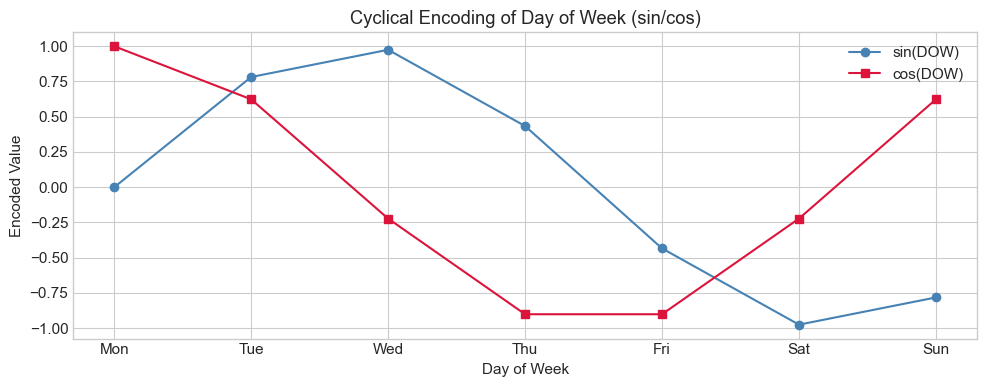


Interpretation: Monday (DOW=0) and Sunday (DOW=6) are cyclically adjacent
because sin(0) ≈ sin(2π) — the circular structure is preserved.


In [6]:
# Visualise cyclical encoding correctness
dow_sample = pd.DataFrame({
    'DOW': range(7),
    'DOW_Name': ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],
    'sin': np.sin(2*np.pi*np.arange(7)/7),
    'cos': np.cos(2*np.pi*np.arange(7)/7)
})

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dow_sample['DOW_Name'], dow_sample['sin'], 'o-', label='sin(DOW)', color='steelblue')
ax.plot(dow_sample['DOW_Name'], dow_sample['cos'], 's-', label='cos(DOW)', color='crimson')
ax.set_title('Cyclical Encoding of Day of Week (sin/cos)')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Encoded Value')
ax.legend()
plt.tight_layout()
plt.show()

print("\nInterpretation: Monday (DOW=0) and Sunday (DOW=6) are cyclically adjacent")
print("because sin(0) ≈ sin(2π) — the circular structure is preserved.")

---
## 5. Autoregressive Lag Features

**Why lags?** Autoregressive models predict `y_t` from `y_{t-k}`. The ACF analysis in NB01 confirmed significant autocorrelation at lags 1, 2, 3, 7, 14, 21.

**Leakage rule:** Lag-k for day t = Revenue of day (t-k). Since t-k < t, no future information is used.

In [7]:
LAG_DAYS = [1, 2, 3, 7, 14, 21]

for k in LAG_DAYS:
    col_name = f'lag_{k}'
    df_feat[col_name] = df_feat['Revenue'].shift(k)

lag_features = [f'lag_{k}' for k in LAG_DAYS]
print(f"Lag features created: {lag_features}")

# Show that the first 21 rows will have NaN lags (we will drop them)
print(f"\nRows with NaN after lagging (to be dropped): {df_feat[lag_features].isna().any(axis=1).sum()}")
print("(Expected: 21 rows — equal to max lag depth)")

Lag features created: ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21']

Rows with NaN after lagging (to be dropped): 21
(Expected: 21 rows — equal to max lag depth)


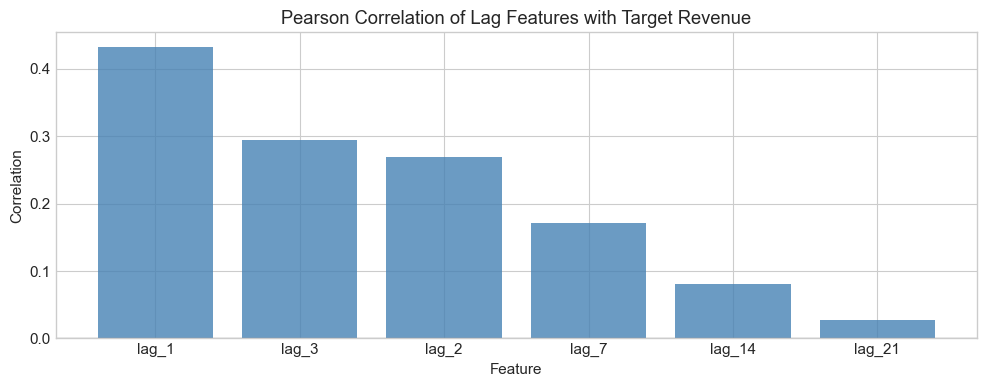


Lag Feature Correlations with Revenue:
  lag_1     : +0.4326
  lag_3     : +0.2943
  lag_2     : +0.2693
  lag_7     : +0.1707
  lag_14    : +0.0813
  lag_21    : +0.0271


In [8]:
# Correlation of lags with target (on non-NaN rows)
temp_corr = df_feat[['Revenue'] + lag_features].dropna()
lag_corr = temp_corr.corr()['Revenue'].drop('Revenue').sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['steelblue' if v > 0 else 'crimson' for v in lag_corr.values]
ax.bar(lag_corr.index, lag_corr.values, color=colors, alpha=0.8)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Pearson Correlation of Lag Features with Target Revenue')
ax.set_xlabel('Feature')
ax.set_ylabel('Correlation')
plt.tight_layout()
plt.show()

print("\nLag Feature Correlations with Revenue:")
for feat, val in lag_corr.items():
    print(f"  {feat:<10}: {val:+.4f}")

---
## 6. Rolling Window Statistics (Leakage-Free)

**Key design decision:** Rolling windows are computed on the *shifted* revenue series (shift=1) so that the window for day t only includes days up to t-1.

Without the shift, `.rolling(7).mean()` at position t would include day t's own value → **direct target leakage**.

$$\text{roll7\_mean}_t = \text{mean}(y_{t-7}, y_{t-6}, \ldots, y_{t-1})$$

In [9]:
# Shift revenue by 1 first — then compute rolling statistics
rev_shifted = df_feat['Revenue'].shift(1)

WINDOWS = [7, 14, 21]

for w in WINDOWS:
    df_feat[f'roll{w}_mean'] = rev_shifted.rolling(w, min_periods=1).mean()
    df_feat[f'roll{w}_std']  = rev_shifted.rolling(w, min_periods=2).std()
    df_feat[f'roll{w}_max']  = rev_shifted.rolling(w, min_periods=1).max()
    df_feat[f'roll{w}_min']  = rev_shifted.rolling(w, min_periods=1).min()

# 7-day sum (total weekly revenue context)
df_feat['roll7_sum'] = rev_shifted.rolling(7, min_periods=1).sum()

rolling_features = (
    [f'roll{w}_mean' for w in WINDOWS] +
    [f'roll{w}_std'  for w in WINDOWS] +
    [f'roll{w}_max'  for w in WINDOWS] +
    [f'roll{w}_min'  for w in WINDOWS] +
    ['roll7_sum']
)

print(f"Rolling features created: {len(rolling_features)}")
print(rolling_features)

Rolling features created: 13
['roll7_mean', 'roll14_mean', 'roll21_mean', 'roll7_std', 'roll14_std', 'roll21_std', 'roll7_max', 'roll14_max', 'roll21_max', 'roll7_min', 'roll14_min', 'roll21_min', 'roll7_sum']


---
## 7. Feature Matrix Assembly & Validation

In [10]:
ALL_FEATURES = calendar_features + lag_features + rolling_features + ['is_closed']

# Drop rows with NaN (initial window period)
df_model = df_feat[['Date', 'Revenue'] + ALL_FEATURES].dropna().reset_index(drop=True)

print(f"Feature matrix shape: {df_model.shape}")
print(f"Features: {len(ALL_FEATURES)}")
print(f"Date range: {df_model['Date'].min().date()} → {df_model['Date'].max().date()}")
print(f"Dropped (warm-up) rows: {len(df_feat) - len(df_model)}")
print()
print("NaN check after dropna:")
print(df_model[ALL_FEATURES].isna().sum().sum(), "NaN values remaining (expect 0)")

Feature matrix shape: (874, 34)
Features: 32
Date range: 2024-04-17 → 2026-09-07
Dropped (warm-up) rows: 21

NaN check after dropna:
0 NaN values remaining (expect 0)


Feature groups summary:
  Calendar features   : 12
  Lag features        : 6
  Rolling features    : 13
  Binary indicators   : 1 (is_closed)
  TOTAL               : 32



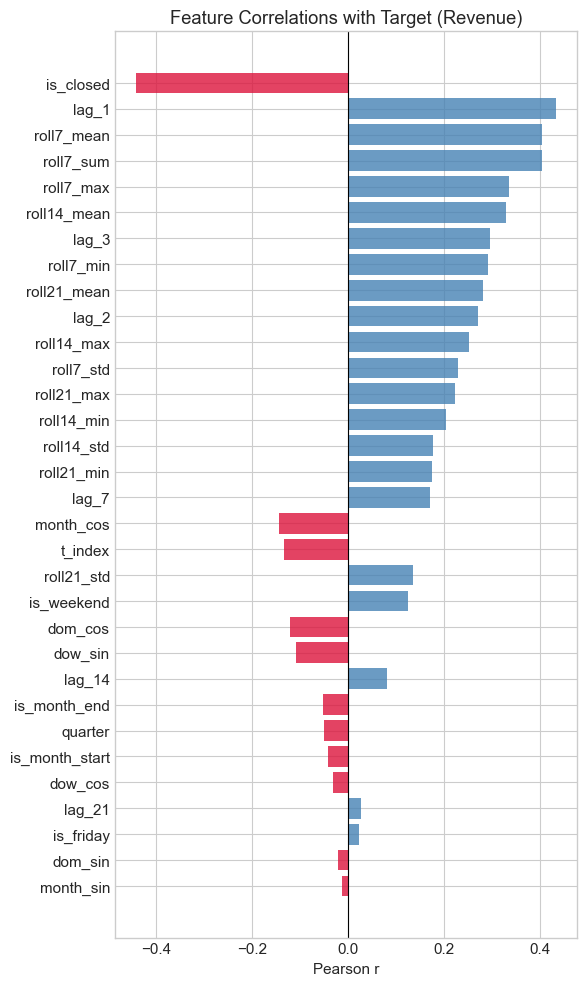

In [11]:
print("Feature groups summary:")
print(f"  Calendar features   : {len(calendar_features)}")
print(f"  Lag features        : {len(lag_features)}")
print(f"  Rolling features    : {len(rolling_features)}")
print(f"  Binary indicators   : 1 (is_closed)")
print(f"  TOTAL               : {len(ALL_FEATURES)}")
print()

# Feature-target correlation heatmap
feat_corr = df_model[['Revenue'] + ALL_FEATURES].corr()['Revenue'].drop('Revenue').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(6, 10))
colors = ['steelblue' if v > 0 else 'crimson' for v in feat_corr.values]
ax.barh(feat_corr.index[::-1], feat_corr.values[::-1], color=colors[::-1], alpha=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Feature Correlations with Target (Revenue)')
ax.set_xlabel('Pearson r')
plt.tight_layout()
plt.show()

---
## 8. Leakage Verification Test

A critical test: we verify that **no feature uses future target values**. The method is to check that the Pearson correlation between each feature at time t and the *next day's* revenue is not suspiciously high (which would indicate forward leakage).

In [12]:
df_leakage = df_model.copy()
df_leakage['Revenue_next'] = df_leakage['Revenue'].shift(-1)  # tomorrow's revenue
df_leakage = df_leakage.dropna(subset=['Revenue_next'])

# If any feature correlates PERFECTLY with Revenue_next, that is leakage
leak_corr = df_leakage[ALL_FEATURES].corrwith(df_leakage['Revenue_next']).abs().sort_values(ascending=False)

print("Top 10 features by correlation with NEXT DAY revenue:")
print(leak_corr.head(10))
print()
print(f"Maximum correlation with next-day revenue: {leak_corr.max():.4f}")
if leak_corr.max() > 0.99:
    print("⚠️  WARNING: Possible leakage detected! Investigate further.")
else:
    print("✅ No leakage detected. All features are using past-only information.")

Top 10 features by correlation with NEXT DAY revenue:
roll7_sum      0.325307
roll7_mean     0.325307
is_closed      0.301414
lag_2          0.288876
roll14_mean    0.272859
lag_1          0.272210
roll7_max      0.263402
lag_3          0.237622
roll7_min      0.237161
roll21_mean    0.237019
dtype: float64

Maximum correlation with next-day revenue: 0.3253
✅ No leakage detected. All features are using past-only information.


---
## 9. Save Feature Matrices

In [13]:
# Save the feature matrix
OUT_PATH = '../data/processed/revenue_feature_matrix.csv'
df_model.to_csv(OUT_PATH, index=False)
print(f"Saved: {OUT_PATH}  ({len(df_model):,} rows × {len(df_model.columns)} cols)")

# Save feature column names for reproducibility
import json
meta = {
    'feature_cols': ALL_FEATURES,
    'target_col': 'Revenue',
    'date_col': 'Date',
    'n_rows': len(df_model),
    'date_min': str(df_model['Date'].min().date()),
    'date_max': str(df_model['Date'].max().date()),
    'author': 'IT24102664'
}
META_PATH = '../data/processed/revenue_feature_meta.json'
with open(META_PATH, 'w') as f:
    json.dump(meta, f, indent=2)
print(f"Saved: {META_PATH}")

Saved: ../data/processed/revenue_feature_matrix.csv  (874 rows × 34 cols)
Saved: ../data/processed/revenue_feature_meta.json


---
## 10. Feature Engineering Decision Log

| Decision | Rationale | Alternative Considered | Why Rejected |
|---|---|---|---|
| Cyclical sin/cos encoding for DOW/month | Preserves circular proximity (Sun adjacent to Mon) | Integer encoding (0–6) | Linear distance implies Mon (0) and Sun (6) are far apart — misleads linear models |
| Lags at t-1, t-2, t-3, t-7, t-14, t-21 | ACF analysis in NB01 shows significant autocorrelation at these lags | Lags t-1 to t-30 exhaustively | Curse of dimensionality; correlated lags cause multicollinearity |
| Rolling windows shifted by 1 before computation | Prevents target leakage | Unshifted rolling windows | Including t's own value in the rolling window leaks the target |
| `is_closed` binary flag | Signals unusual days without corrupting revenue signal | Removing zero-revenue days | Removing days destroys the continuous calendar needed for lag features |
| Drop first 21 rows (warm-up period) | Lag-21 requires 21 past observations | Impute NaN lags with mean | Mean imputation introduces artificial signal; chronological integrity preserved |
| `t_index` ordinal trend feature | Captures slow secular revenue growth trend | Year one-hot encoding | One-hot would create three sparse columns; `t_index` is more parsimonious |

### Responsible AI Note (IT24102664)
All feature engineering decisions are transparent and documented above. No features derived from external data sources that could introduce demographic or socioeconomic bias. The dataset covers a single Sri Lankan restaurant; generalisation to other restaurants requires domain-specific re-engineering.

**AI-use declaration:** Generative AI was used to assist with boilerplate code comments only. All analytical logic and decisions are the author's own.